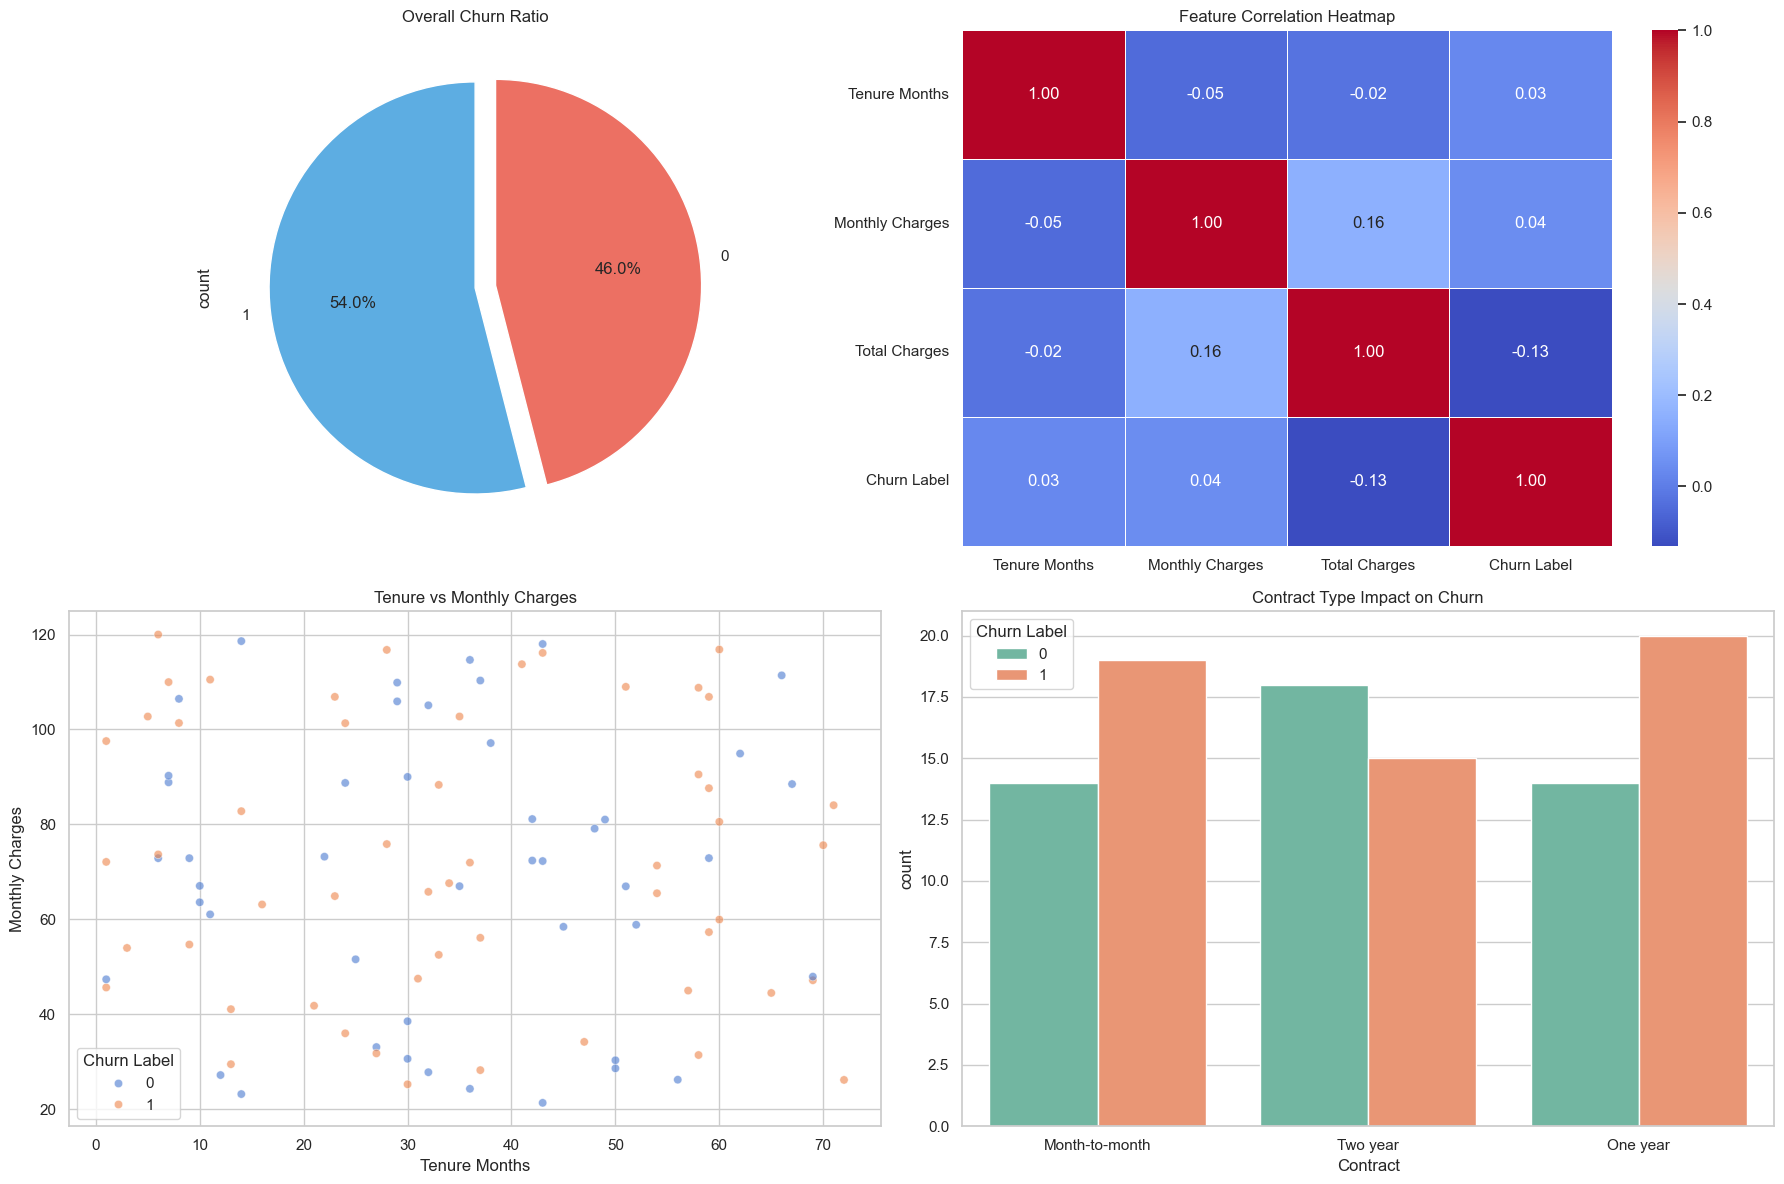

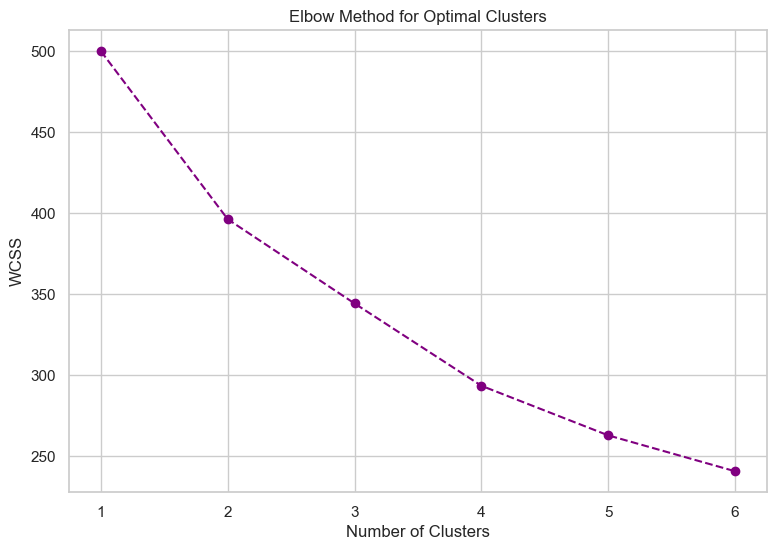

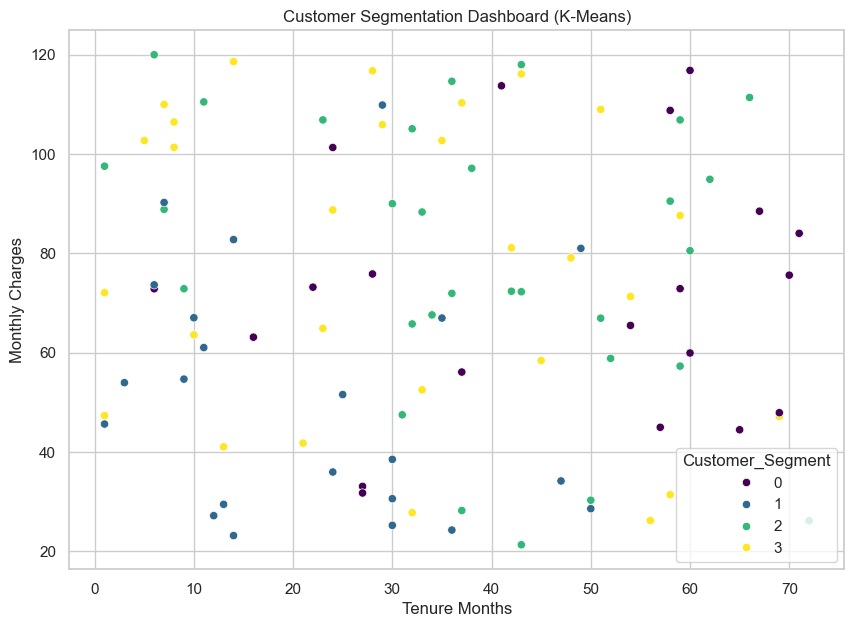


Churn Rate by Customer Segment:
Customer_Segment
0    70.000000
1    40.909091
2    50.000000
3    57.142857
Name: Churn Label, dtype: float64


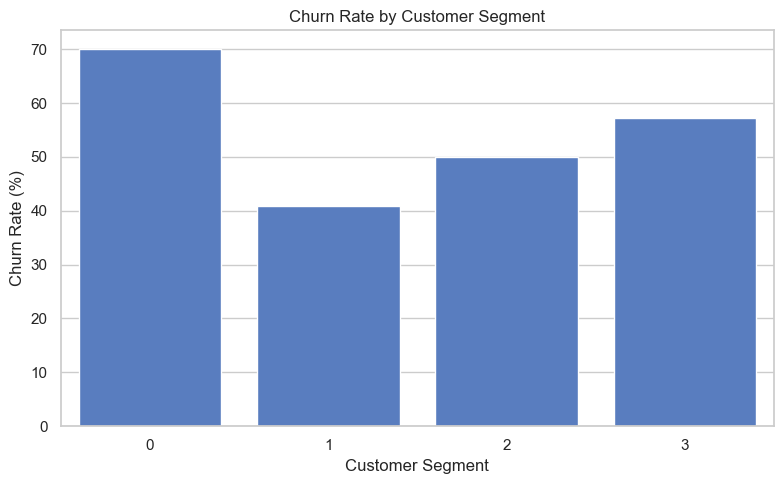


Model Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.33      0.43         9
           1       0.60      0.82      0.69        11

    accuracy                           0.60        20
   macro avg       0.60      0.58      0.56        20
weighted avg       0.60      0.60      0.57        20



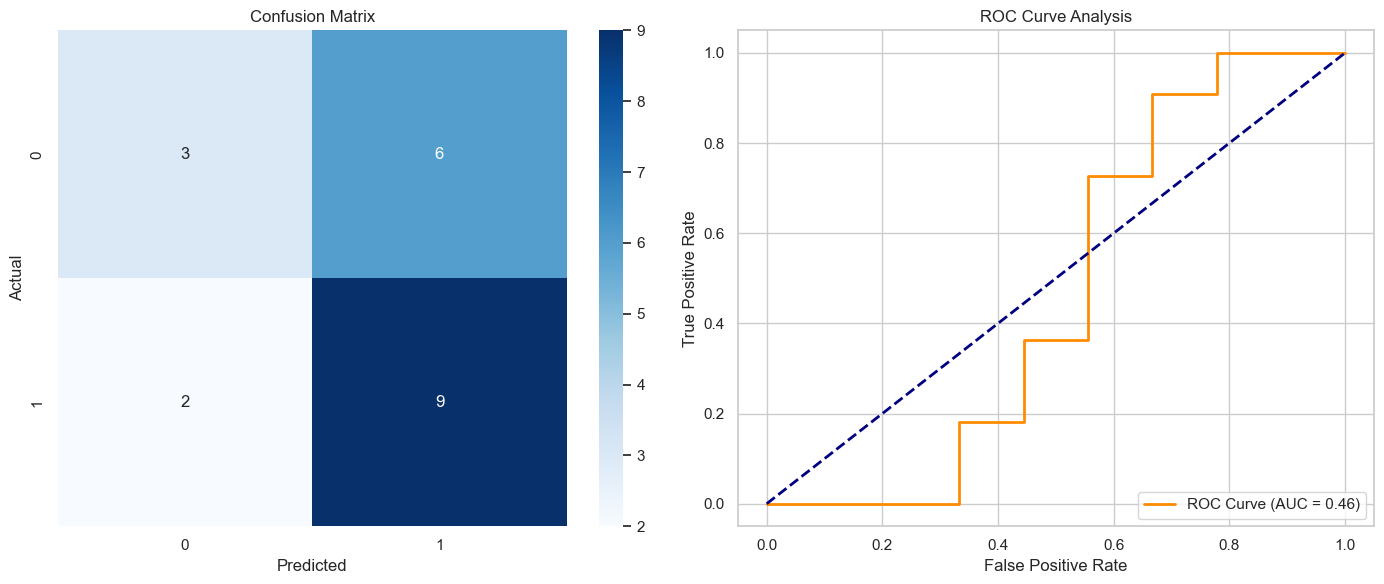

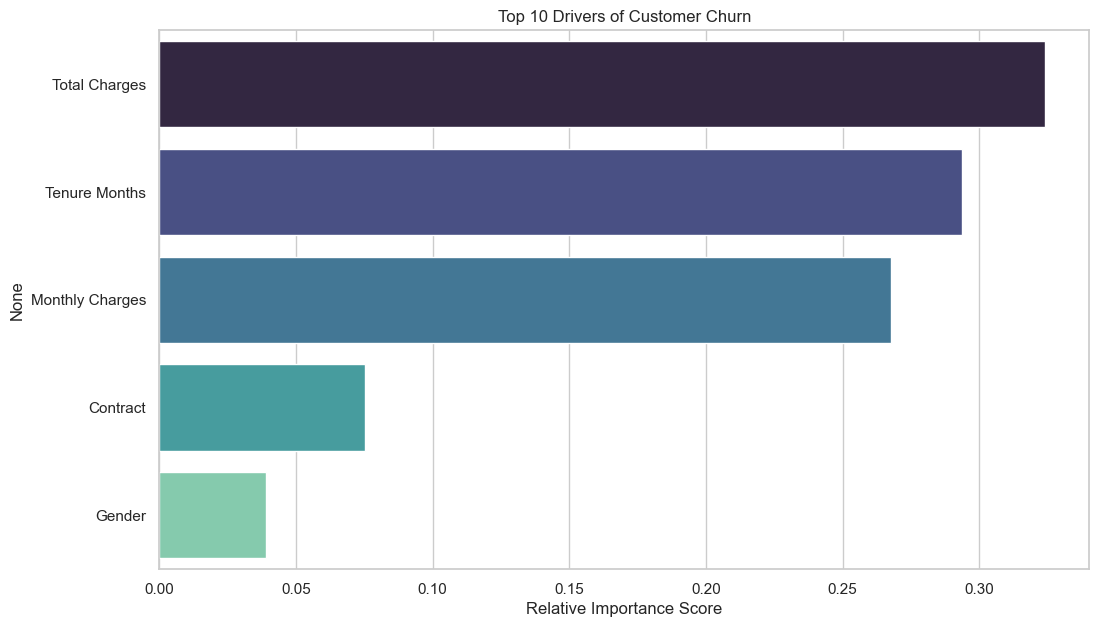

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", palette="muted")


# ============================================================
# CREATE DATASET
# ============================================================

data = {
    'customerID': [f'C{i}' for i in range(1, 101)],
    'Gender': np.random.choice(['Male', 'Female'], 100),
    'Tenure Months': np.random.randint(1, 73, 100),
    'Monthly Charges': np.random.uniform(20, 120, 100),
    'Total Charges': np.random.uniform(50, 5000, 100).astype(str),
    'Contract': np.random.choice(
        ['Month-to-month', 'One year', 'Two year'], 100
    ),
    'Churn Label': np.random.choice([0, 1], 100)
}

df = pd.DataFrame(data)


# ============================================================
# DATA PREPROCESSING
# ============================================================

# Add some missing values for testing
for _ in range(5):
    idx = np.random.randint(0, len(df))
    df.loc[idx, 'Total Charges'] = ' '

df['Total Charges'] = df['Total Charges'].replace(' ', np.nan)
df['Total Charges'] = df['Total Charges'].astype(float)
df['Total Charges'] = df['Total Charges'].fillna(
    df['Total Charges'].median()
)

# Remove customer ID
df.drop(columns=['customerID'], inplace=True)


# ============================================================
# EXPLORATORY DATA ANALYSIS
# ============================================================

plt.figure(figsize=(18, 12))

# Churn ratio
plt.subplot(2, 2, 1)
df['Churn Label'].value_counts().plot.pie(
    autopct='%1.1f%%',
    startangle=90,
    colors=['#5dade2', '#ec7063'],
    explode=(0, 0.1)
)
plt.title('Overall Churn Ratio')


# Correlation heatmap
plt.subplot(2, 2, 2)

numeric_df = df.select_dtypes(include=[np.number])

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Feature Correlation Heatmap')


# Tenure vs Monthly Charges
plt.subplot(2, 2, 3)

sns.scatterplot(
    data=df,
    x='Tenure Months',
    y='Monthly Charges',
    hue='Churn Label',
    alpha=0.6
)

plt.title('Tenure vs Monthly Charges')


# Contract vs Churn
plt.subplot(2, 2, 4)

sns.countplot(
    data=df,
    x='Contract',
    hue='Churn Label',
    palette='Set2'
)

plt.title('Contract Type Impact on Churn')

plt.tight_layout()
plt.show()


# ============================================================
# CATEGORICAL ENCODING
# ============================================================

le = LabelEncoder()

categorical_cols = df.select_dtypes(
    include=['object']
).columns

for col in categorical_cols:
    df[col] = le.fit_transform(df[col])


# ============================================================
# PREPARE DATA FOR MODELING
# ============================================================

X = df.drop(columns=['Churn Label'])
y = df['Churn Label']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


# ============================================================
# ELBOW METHOD
# ============================================================

wcss = []

for i in range(1, 7):

    kmeans = KMeans(
        n_clusters=i,
        init='k-means++',
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)


plt.figure(figsize=(9, 6))

plt.plot(
    range(1, 7),
    wcss,
    marker='o',
    linestyle='--',
    color='purple'
)

plt.title('Elbow Method for Optimal Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')

plt.show()


# ============================================================
# K-MEANS CUSTOMER SEGMENTATION
# ============================================================

kmeans_final = KMeans(
    n_clusters=4,
    init='k-means++',
    random_state=42,
    n_init=10
)

df['Customer_Segment'] = kmeans_final.fit_predict(X_scaled)


# Customer segmentation graph

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x='Tenure Months',
    y='Monthly Charges',
    hue='Customer_Segment',
    palette='viridis',
    legend='full'
)

plt.title('Customer Segmentation Dashboard (K-Means)')
plt.show()


# ============================================================
# MY CONTRIBUTION
# CUSTOMER SEGMENT CHURN RATE ANALYSIS
# ============================================================

segment_churn = (
    df.groupby('Customer_Segment')['Churn Label'].mean()
    * 100
)

print("\nChurn Rate by Customer Segment:")

print(segment_churn)


# Churn rate graph

plt.figure(figsize=(8, 5))

sns.barplot(
    x=segment_churn.index,
    y=segment_churn.values
)

plt.title('Churn Rate by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Churn Rate (%)')

plt.tight_layout()
plt.show()


# ============================================================
# TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# ============================================================
# RANDOM FOREST HYPERPARAMETER TUNING
# ============================================================

param_dist = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

rf = RandomForestClassifier(
    random_state=42
)

rf_tuned = RandomizedSearchCV(
    rf,
    param_distributions=param_dist,
    n_iter=5,
    cv=3,
    random_state=42
)

rf_tuned.fit(X_train, y_train)


# Best model

best_model = rf_tuned.best_estimator_


# Predictions

y_pred = best_model.predict(X_test)

y_prob = best_model.predict_proba(X_test)[:, 1]


# ============================================================
# MODEL EVALUATION
# ============================================================

print("\nModel Classification Report:")

print(
    classification_report(
        y_test,
        y_pred
    )
)


# ============================================================
# CONFUSION MATRIX & ROC CURVE
# ============================================================

plt.figure(figsize=(14, 6))


# Confusion Matrix

plt.subplot(1, 2, 1)

sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')


# ROC Curve

plt.subplot(1, 2, 2)

fpr, tpr, _ = roc_curve(
    y_test,
    y_prob
)

auc_score = roc_auc_score(
    y_test,
    y_prob
)

plt.plot(
    fpr,
    tpr,
    color='darkorange',
    lw=2,
    label=f'ROC Curve (AUC = {auc_score:.2f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    color='navy',
    lw=2,
    linestyle='--'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Analysis')
plt.legend(loc="lower right")


plt.tight_layout()
plt.show()


# ============================================================
# FEATURE IMPORTANCE
# ============================================================

importances = best_model.feature_importances_

indices = np.argsort(importances)[::-1]

plt.figure(figsize=(12, 7))

sns.barplot(
    x=importances[indices][:10],
    y=X.columns[indices][:10],
    palette='mako'
)

plt.title('Top 10 Drivers of Customer Churn')
plt.xlabel('Relative Importance Score')

plt.show()

Churn Rate by Customer Segment:
Customer_Segment
0    70.000000
1    40.909091
2    50.000000
3    57.142857
Name: Churn Label, dtype: float64


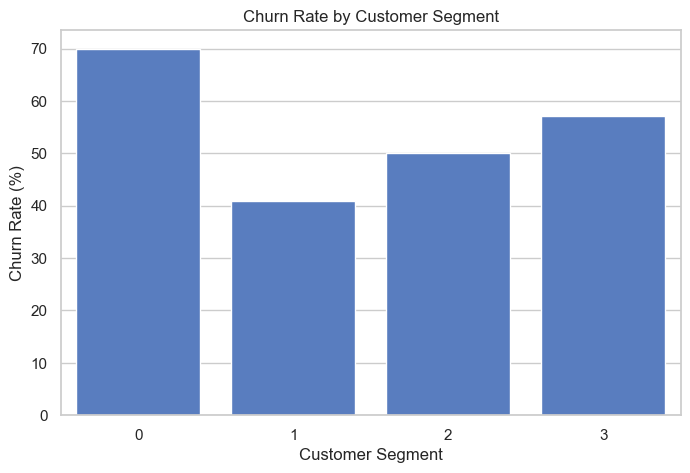

In [15]:
segment_churn = df.groupby('Customer_Segment')['Churn Label'].mean() * 100

print("Churn Rate by Customer Segment:")
print(segment_churn)

plt.figure(figsize=(8, 5))
sns.barplot(x=segment_churn.index, y=segment_churn.values)

plt.title("Churn Rate by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Churn Rate (%)")
plt.show()